**数据分析流程**

采集数据$\to$确定分析方向$\to$导入数据$\to$数据清洗$\to$数据分析$\to$数据可视化

# 房地产市场洞察与价值评估

In [81]:
#导入库
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['Microsoft YaHei']

In [82]:
#导入数据
df = pd.read_csv('data/house_sales.csv')

In [83]:
#数据概览
print('总记录数：',len(df))
print('总字段数量：',len(df.columns))
df.info()

总记录数： 106118
总字段数量： 12
<class 'pandas.DataFrame'>
RangeIndex: 106118 entries, 0 to 106117
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   city        106118 non-null  str  
 1   address     104452 non-null  str  
 2   area        105324 non-null  str  
 3   floor       104024 non-null  str  
 4   name        105564 non-null  str  
 5   price       105564 non-null  str  
 6   province    106118 non-null  str  
 7   rooms       104036 non-null  str  
 8   toward      105240 non-null  str  
 9   unit        105564 non-null  str  
 10  year        57736 non-null   str  
 11  origin_url  105564 non-null  str  
dtypes: str(12)
memory usage: 9.7 MB


In [84]:
#数据清洗
#删除无用列
df.drop(columns = 'origin_url', inplace = True)
#删除缺失值
df.dropna(inplace = True)
#删除重复值
df.drop_duplicates(inplace = True)

In [85]:
#类型转换
#面积的数据类型转换
df['area'] = df['area'].str.replace('㎡','').astype(float)
#售价的数据类型转换
df['price'] = df['price'].str.replace('万','').astype(float)
#朝向的数据类型转换
df['toward'] = df['toward'].astype("category")
#每平价格的数据类型转换
df['unit'] = df['unit'].str.replace('元/㎡','').astype(float)
#时间的数据类型转换
df['year'] = df['year'].str.replace('年建', '').astype(int)

In [86]:
#异常值处理
Q1 = df['price'].quantile(0.25)
Q2 = df['price'].quantile(0.75)
IQR = Q2-Q1
lowest_price = Q1 - 1.5 * IQR
highest_price = Q2 + 1.5 * IQR
df = df[(df['price'] > lowest_price) & (df['price'] < highest_price)]

In [87]:
#特征构造
#地区district
df['district'] = df['address'].str.split('-').str[0]
#楼层floor_type
#df['floor_type'] = df['floor'].str.split('（').str[0]
def fun1(str1):
    if pd.isna(str1):
        return '未知'
    elif '低' in str1:
        return '低楼层'
    elif '中' in str1:
        return '中楼层'
    elif '高' in str1:
        return '高楼层'
df['floor_type'] = df['floor'].apply(fun1).astype('category')
#是否是直辖市zxs
df['zxs'] = df['province'].apply(lambda x: True if x=='直辖市' else False)
#卧室数量bedrooms
#df['bedrooms'] = df['rooms'].str.split('室').str[0]
df['bedrooms'] = df['rooms'].str.extract(r'(\d+)室')
#客厅数量livingrooms
#df['livingrooms'] = df['rooms'].str.split('室').str[1].str.split('厅').str[0]
#正则表达式extract提取数字
df['livingrooms'] = df['rooms'].str.extract(r'(\d+)厅')
#楼龄building_age
df['building_age'] = 2025-df['year']
#价格的分段price_labels
df['price_labels'] = pd.cut(df['price'], bins = 4, labels = ['低价', '中价', '高价', '豪华'])

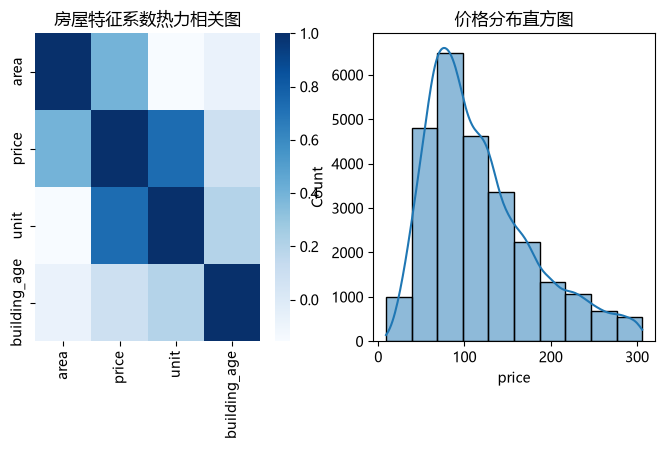

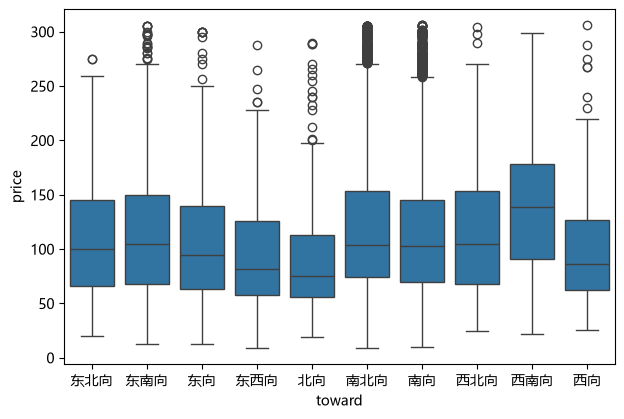

In [88]:
#问题分析及可视化
c = df[['area', 'price', 'unit', 'building_age']].corr()
plt.figure(figsize = (8,4))
plt.subplot(121)
sns.heatmap(c, cmap='Blues')
plt.title('房屋特征系数热力相关图')
plt.subplot(122)
plt.title('价格分布直方图')
sns.histplot(data = df, x= 'price',bins = 10,kde = True)
df.groupby('toward').agg({
    'price':['mean','median'],
    'unit':['mean','median']
})
plt.figure(figsize = (12,8))
plt.subplot(223)
sns.boxplot(data=df, x = 'toward', y = 'price')
plt.tight_layout()
plt.show()